# Value at Risk (VaR) - Multi-Asset Portfolio: Monte Carlo Simulation

## Monte Carlo Simulation Approach

**Theory:** Monte Carlo Simulation generates a large number of random scenarios using estimated return distribution parameters, including the mean vector and covariance matrix, to simulate potential future portfolio returns.

## Key Steps

1. **Parameter Estimation:** Estimate the mean return vector $\mu$ and covariance matrix $\Sigma$ from historical data.

2. **Cholesky Decomposition:** Decompose the covariance matrix as:

   $$
   \Sigma=LL^T
   $$

   where $L$ is a lower-triangular matrix.

3. **Generate Correlated Returns:** Generate correlated asset-return scenarios using:

   $$
   R_{\text{sim}}=\mu+LZ
   $$

   where $Z\sim\mathcal{N}(0,I)$ is a vector of independent standard normal random variables.

4. **Compute Portfolio Returns:** For each simulation, calculate:

   $$
   R_{p,\text{sim}}=w^TR_{\text{sim}}
   $$

   where $w$ is the portfolio weight vector.

5. **Calculate VaR and ES:** Estimate both measures from the empirical distribution of simulated portfolio returns.

## Formulas

**Correlated Return Simulation:**

$$
R_{\text{sim}}^{(s)}=\mu+LZ^{(s)},
\qquad Z^{(s)}\sim\mathcal{N}(0,I)
$$

where $s=1,2,\ldots,N$ represents the simulation number and $N$ is the total number of simulations.

**Value at Risk (VaR):**

$$
\operatorname{VaR}_{\alpha}^{\text{MC}}
=
-\widehat{Q}_{1-\alpha}(R_{p,\text{sim}})
$$

**Expected Shortfall (ES):**

$$
\operatorname{ES}_{\alpha}^{\text{MC}}
=
-\mathbb{E}\left[
R_{p,\text{sim}}
\mid
R_{p,\text{sim}}\leq
\widehat{Q}_{1-\alpha}(R_{p,\text{sim}})
\right]
$$

Here, $\widehat{Q}_{1-\alpha}(R_{p,\text{sim}})$ is the empirical lower-tail quantile of simulated portfolio returns.

**Note:** Cholesky decomposition incorporates the covariance structure into the simulated asset returns, preserving the modeled variances and correlations across scenarios. VaR and ES are expressed as positive losses.

[*********************100%***********************]  4 of 4 completed



=== Monte Carlo Risk Summary (Based on 10000 Simulations) ===
Monte Carlo VaR (95%): 2.15%
Monte Carlo ES (95%):  2.70%


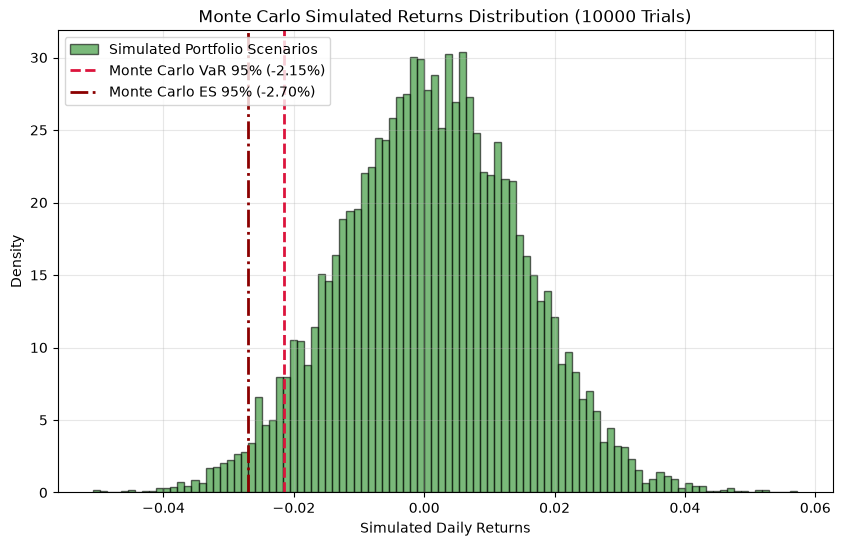

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Download multi-asset data
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN"]
start_date = "2023-01-01"
end_date = "2026-01-01"

print(f"Downloading historical data for {tickers}...")
raw_data = yf.download(tickers, period="3y", auto_adjust=True)

# 2. Extract Adjusted Close and calculate daily returns
adj_close = raw_data["Close"]
returns = adj_close.pct_change().dropna()

# 3. Define portfolio & simulation configurations
weights = np.array([0.40, 0.30, 0.15, 0.15])  # Allocation weights
confidence_level = 0.95
num_simulations = 10000  # Number of random scenarios to run

# 4. Gather statistical parameters
mean_returns = returns.mean()
cov_matrix = returns.cov()

# 5. Cholesky Decomposition (Crucial for multi-asset simulation)
# This mathematical matrix technique helps us generate random variables 
# that preserve the real-world correlations between Apple, Microsoft, etc.
L = np.linalg.cholesky(cov_matrix)

# 6. Run the Monte Carlo Simulation
# Generate completely random standard normal variables
random_noise = np.random.normal(size=(len(tickers), num_simulations))

# Correlate the random variables using the Cholesky matrix
# Daily Return = Mean + (Cholesky Matrix * Random Noise)
simulated_asset_returns = mean_returns.to_numpy().reshape(-1, 1) + np.dot(L, random_noise)

# Aggregate asset returns into portfolio returns by applying weights
simulated_portfolio_returns = np.dot(weights, simulated_asset_returns)


# EXTRACT MONTE CARLO RISK METRICS

# Sort the 10,000 simulated returns and find the 5th percentile cutoff (for 95% confidence)
mc_var = -np.percentile(simulated_portfolio_returns, (1 - confidence_level) * 100)

# Filter scenarios that broke past the Monte Carlo VaR threshold
mc_tail_losses = simulated_portfolio_returns[simulated_portfolio_returns <= -mc_var]

# Average of those simulated breach scenarios
mc_es = -np.mean(mc_tail_losses)


# PRINT & PLOT RESULTS

print(f"\n=== Monte Carlo Risk Summary (Based on {num_simulations} Simulations) ===")
print(f"Monte Carlo VaR (95%): {mc_var * 100:.2f}%")
print(f"Monte Carlo ES (95%):  {mc_es * 100:.2f}%")

# Plotting the simulated distribution
plt.figure(figsize=(10, 6))
plt.hist(
    simulated_portfolio_returns,
    bins=100,
    alpha=0.6,
    color="forestgreen",
    edgecolor="black",
    density=True,
    label="Simulated Portfolio Scenarios",
)

plt.axvline(
    -mc_var,
    color="crimson",
    linestyle="dashed",
    linewidth=2,
    label=f"Monte Carlo VaR 95% ({-mc_var*100:.2f}%)",
)
plt.axvline(
    -mc_es,
    color="darkred",
    linestyle="dashdot",
    linewidth=2,
    label=f"Monte Carlo ES 95% ({-mc_es*100:.2f}%)",
)

plt.title(f"Monte Carlo Simulated Returns Distribution ({num_simulations} Trials)")
plt.xlabel("Simulated Daily Returns")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()


In [4]:
raw_data

Price            Close                                            High  \
Ticker            AAPL        AMZN       GOOGL        MSFT        AAPL   
Date                                                                     
2023-10-27  165.975159  127.739998  121.018433  322.262115  166.705289   
2023-10-30  168.017548  132.710007  123.286850  329.590454  168.885809   
2023-10-31  168.491119  133.089996  122.910423  330.372162  168.619374   
2023-11-01  171.648438  137.000000  125.258080  338.149963  171.904962   
2023-11-02  175.200394  138.070007  126.288284  340.348511  175.407583   
...                ...         ...         ...         ...         ...   
2026-10-21  343.989990  262.369995  334.760010  532.950012  345.250000   
2026-10-22  348.220001  250.380005  324.220001  521.080017  348.359985   
2026-10-23  347.730011  248.000000  320.209991  524.510010  351.730011   
2026-10-26  343.910004  249.089996  316.799988  532.599976  347.089996   
2026-10-27  347.390015  254.149994  323.329987  532.590027  347.779999   

Price                                                  Low              \
Ticker            AMZN       GOOGL        MSFT        AAPL        AMZN   
Date                                                                     
2023-10-27  130.020004  122.147686  329.013980  164.603708  125.519997   
2023-10-30  133.000000  124.217992  331.681493  166.616499  128.559998   
2023-10-31  133.570007  124.188265  331.241808  165.659409  131.710007   
2023-11-01  137.350006  125.297703  339.469074  167.849808  133.710007   
2023-11-02  138.809998  127.764238  340.846819  173.118550  136.470001   
...                ...         ...         ...         ...         ...   
2026-10-21  264.359985  337.269989  533.280029  338.829987  259.290009   
2026-10-22  258.410004  331.429993  533.599976  342.279999  248.000000   
2026-10-23  250.009995  324.529999  525.770020  345.750000  246.449997   
2026-10-26  250.789993  321.480011  533.250000  341.029999  247.229996   
2026-10-27  254.669998  323.875000  534.700012  342.390015  248.710098   

Price                                     Open                          \
Ticker           GOOGL        MSFT        AAPL        AMZN       GOOGL   
Date                                                                     
2023-10-27  119.076908  320.884381  164.682643  126.199997  121.721739   
2023-10-30  121.592969  324.235856  166.764506  129.720001  122.048632   
2023-10-31  121.533526  327.030447  167.090071  132.750000  123.881182   
2023-11-01  122.553817  331.876876  168.718070  133.960007  122.900516   
2023-11-02  125.733565  336.879737  173.177747  138.729996  127.209518   
...                ...         ...         ...         ...         ...   
2026-10-21  330.380005  525.020020  339.359985  262.709991  336.980011   
2026-10-22  322.000000  520.299988  344.940002  258.179993  330.459991   
2026-10-23  320.179993  515.700012  349.119995  248.850006  321.149994   
2026-10-26  316.600006  521.690002  343.920013  249.470001  320.890015   
2026-10-27  316.898499  528.330994  343.165009  250.350006  316.980011   

Price                     Volume                                 
Ticker            MSFT      AAPL       AMZN     GOOGL      MSFT  
Date                                                             
2023-10-27  322.867922  58499100  125309300  44566500  29856500  
2023-10-30  325.779714  51131000   72485500  28940100  22828100  
2023-10-31  331.095247  44846000   51589400  26292300  20265300  
2023-11-01  332.013687  56934900   61529400  30082400  28158800  
2023-11-02  339.293210  77334800   52236700  27124600  24348100  
...                ...       ...        ...       ...       ...  
2026-10-21  529.440002  35614100   31214700  29165500  13940100  
2026-10-22  533.140015  46898900   48814000  27748100  21266600  
2026-10-23  517.750000  39539700   25569000  17569600  13671500  
2026-10-26  527.400024  42743600   32696400  23991800  19021000  
2026-10-27  532.349976  2170489